In [1]:
import numpy as np
import pandas as pd
import keras
from keras.models import Sequential
from keras.layers import Dense, Activation, Flatten,Dropout
from keras.layers import Conv2D,LSTM,BatchNormalization,MaxPooling2D,Reshape
from keras.utils import to_categorical
from keras import regularizers
import matplotlib.pyplot as plt

In [2]:
X_test = np.load("Data/X_test.npy")
y_test = np.load("Data/y_test.npy")
person_train_valid = np.load("Data/person_train_valid.npy")
X_train_valid = np.load("Data/X_train_valid.npy")
y_train_valid = np.load("Data/y_train_valid.npy")
person_test = np.load("Data/person_test.npy")

In [3]:
person1_mask = (person_train_valid == 1).flatten()
X_train_valid_p1 = X_train_valid[person1_mask]
y_train_valid_p1 = y_train_valid[person1_mask]

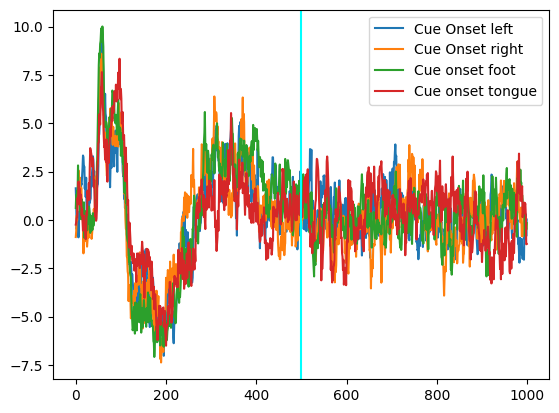

In [4]:
y_train_valid_p1 -= 769
y_test -= 769

## Visualizing the data

ch_data = X_train_valid_p1[:,8,:]


class_0_ind = np.where(y_train_valid_p1 == 0)
ch_data_class_0 = ch_data[class_0_ind]
avg_ch_data_class_0 = np.mean(ch_data_class_0,axis=0)


class_1_ind = np.where(y_train_valid_p1 == 1)
ch_data_class_1 = ch_data[class_1_ind]
avg_ch_data_class_1 = np.mean(ch_data_class_1,axis=0)

class_2_ind = np.where(y_train_valid_p1 == 2)
ch_data_class_2 = ch_data[class_2_ind]
avg_ch_data_class_2 = np.mean(ch_data_class_2,axis=0)

class_3_ind = np.where(y_train_valid_p1 == 3)
ch_data_class_3 = ch_data[class_3_ind]
avg_ch_data_class_3 = np.mean(ch_data_class_3,axis=0)


plt.plot(np.arange(1000),avg_ch_data_class_0)
plt.plot(np.arange(1000),avg_ch_data_class_1)
plt.plot(np.arange(1000),avg_ch_data_class_2)
plt.plot(np.arange(1000),avg_ch_data_class_3)
plt.axvline(x=500, label='line at t=500',c='cyan')

plt.legend(["Cue Onset left", "Cue Onset right", "Cue onset foot", "Cue onset tongue"])

In [5]:
X_train_valid_prep = X_train_valid_p1[:,:,0:500]
X_test_prep = X_test[:,:,0:500]

print(X_train_valid_prep.shape)
print(X_test_prep.shape)
print(y_train_valid_p1.shape)
print(y_test.shape)

(236, 22, 500)
(443, 22, 500)
(236,)
(443,)


In [6]:
# First generating the training and validation indices using random splitting
ind_valid = np.random.choice(236, 50, replace=False)
ind_train = np.array(list(set(range(236)).difference(set(ind_valid))))

# Creating the training and validation sets using the generated indices
(x_train, x_valid) = X_train_valid_prep[ind_train], X_train_valid_prep[ind_valid] 
(y_train, y_valid) = y_train_valid_p1[ind_train], y_train_valid_p1[ind_valid]
print('Shape of training set:',x_train.shape)
print('Shape of validation set:',x_valid.shape)
print('Shape of training labels:',y_train.shape)
print('Shape of validation labels:',y_valid.shape)


# Converting the labels to categorical variables for multiclass classification
y_train = to_categorical(y_train, 4)
y_valid = to_categorical(y_valid, 4)
y_test = to_categorical(y_test, 4)
print('Shape of training labels after categorical conversion:',y_train.shape)
print('Shape of validation labels after categorical conversion:',y_valid.shape)
print('Shape of test labels after categorical conversion:',y_test.shape)

# Adding width of the segment to be 1
x_train = x_train.reshape(x_train.shape[0], x_train.shape[1], x_train.shape[2], 1)
x_valid = x_valid.reshape(x_valid.shape[0], x_valid.shape[1], x_train.shape[2], 1)
x_test = X_test_prep.reshape(X_test_prep.shape[0], X_test_prep.shape[1], X_test_prep.shape[2], 1)
print('Shape of training set after adding width info:',x_train.shape)
print('Shape of validation set after adding width info:',x_valid.shape)
print('Shape of test set after adding width info:',x_test.shape)


# Reshaping the training and validation dataset
x_train = np.swapaxes(x_train, 1,3)
x_train = np.swapaxes(x_train, 1,2)
x_valid = np.swapaxes(x_valid, 1,3)
x_valid = np.swapaxes(x_valid, 1,2)
x_test = np.swapaxes(x_test, 1,3)
x_test = np.swapaxes(x_test, 1,2)
print('Shape of training set after dimension reshaping:',x_train.shape)
print('Shape of validation set after dimension reshaping:',x_valid.shape)
print('Shape of test set after dimension reshaping:',x_test.shape)

Shape of training set: (186, 22, 500)
Shape of validation set: (50, 22, 500)
Shape of training labels: (186,)
Shape of validation labels: (50,)
Shape of training labels after categorical conversion: (186, 4)
Shape of validation labels after categorical conversion: (50, 4)
Shape of test labels after categorical conversion: (443, 4)
Shape of training set after adding width info: (186, 22, 500, 1)
Shape of validation set after adding width info: (50, 22, 500, 1)
Shape of test set after adding width info: (443, 22, 500, 1)
Shape of training set after dimension reshaping: (186, 500, 1, 22)
Shape of validation set after dimension reshaping: (50, 500, 1, 22)
Shape of test set after dimension reshaping: (443, 500, 1, 22)


In [7]:
# Building the CNN model using sequential class
basic_cnn_model = Sequential()

# Conv. block 1
basic_cnn_model.add(Conv2D(filters=100, kernel_size=(3,3), padding='same', activation='elu', input_shape=(500,1,22)))
basic_cnn_model.add(MaxPooling2D(pool_size=(3,1), padding='same')) # Read the keras documentation
basic_cnn_model.add(BatchNormalization())
basic_cnn_model.add(Dropout(0.5))

# Conv. block 2
basic_cnn_model.add(Conv2D(filters=100, kernel_size=(3,3), padding='same', activation='elu'))
basic_cnn_model.add(MaxPooling2D(pool_size=(3,1), padding='same'))
basic_cnn_model.add(BatchNormalization())
basic_cnn_model.add(Dropout(0.5))

# Conv. block 3
basic_cnn_model.add(Conv2D(filters=100, kernel_size=(3,3), padding='same', activation='elu'))
basic_cnn_model.add(MaxPooling2D(pool_size=(3,1), padding='same'))
basic_cnn_model.add(BatchNormalization())
basic_cnn_model.add(Dropout(0.5))

# Conv. block 4
# basic_cnn_model.add(Conv2D(filters=100, kernel_size=(3,3), padding='same', activation='elu'))
# basic_cnn_model.add(MaxPooling2D(pool_size=(3,1), padding='same'))
# basic_cnn_model.add(BatchNormalization())
# basic_cnn_model.add(Dropout(0.5))

# Output layer with Softmax activation
basic_cnn_model.add(Flatten()) # Flattens the input
basic_cnn_model.add(Dense(4, activation='softmax')) # Output FC layer with softmax activation


# Printing the model summary
basic_cnn_model.summary()




Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 500, 1, 100)       19900     
                                                                 
 max_pooling2d (MaxPooling2  (None, 167, 1, 100)       0         
 D)                                                              
                                                                 
 batch_normalization (Batch  (None, 167, 1, 100)       400       
 Normalization)                                                  
                                                                 
 dropout (Dropout)           (None, 167, 1, 100)       0         
                                                                 
 conv2d_1 (Conv2D)           (None, 167, 1, 100)       90100     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 56, 1, 100)       

In [8]:
# Model parameters
learning_rate = 1e-3
epochs = 110
cnn_optimizer = keras.optimizers.legacy.Adam(learning_rate=learning_rate)

In [9]:
 class MyThresholdCallback(keras.callbacks.Callback):
    def __init__(self, threshold):
        super(MyThresholdCallback, self).__init__()
        self.threshold = threshold

    def on_epoch_end(self, epoch, logs=None):
        val_acc = logs["val_accuracy"]
        if val_acc >= self.threshold:
            self.model.stop_training = True

In [10]:
# Compiling the
my_callback = MyThresholdCallback(threshold=0.7)


basic_cnn_model.compile(loss='categorical_crossentropy',
                 optimizer=cnn_optimizer,
                 metrics=['accuracy'])

callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)

# Training and validating the model
basic_cnn_model_results = basic_cnn_model.fit(x_train,
             y_train,
             batch_size=64,
             epochs=epochs,
             validation_data=(x_valid, y_valid), callbacks=[my_callback],verbose=True)

Epoch 1/110


3/3 [==============================] - 3s 377ms/step - loss: 2.4891 - accuracy: 0.2258 - val_loss: 2.0204 - val_accuracy: 0.1600
Epoch 2/110
3/3 [==============================] - 0s 148ms/step - loss: 1.8352 - accuracy: 0.3817 - val_loss: 2.2391 - val_accuracy: 0.1800
Epoch 3/110
3/3 [==============================] - 0s 138ms/step - loss: 1.7959 - accuracy: 0.3548 - val_loss: 2.2404 - val_accuracy: 0.1600
Epoch 4/110
3/3 [==============================] - 0s 150ms/step - loss: 1.7476 - accuracy: 0.3925 - val_loss: 1.9934 - val_accuracy: 0.2200
Epoch 5/110
3/3 [==============================] - 0s 127ms/step - loss: 1.7699 - accuracy: 0.4086 - val_loss: 2.0566 - val_accuracy: 0.2200
Epoch 6/110
3/3 [==============================] - 0s 132ms/step - loss: 1.4326 - accuracy: 0.4624 - val_loss: 2.0738 - val_accuracy: 0.2200
Epoch 7/110
3/3 [==============================] - 0s 144ms/step - loss: 1.5007 - accuracy: 0.4462 - val_loss: 2.1606 - val_accuracy: 0.2000
Epoch 8/110

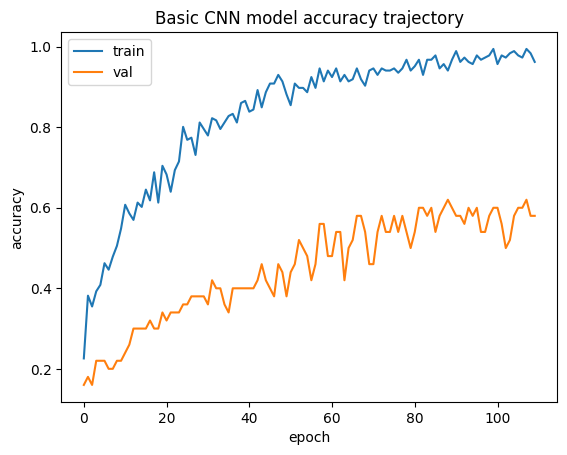

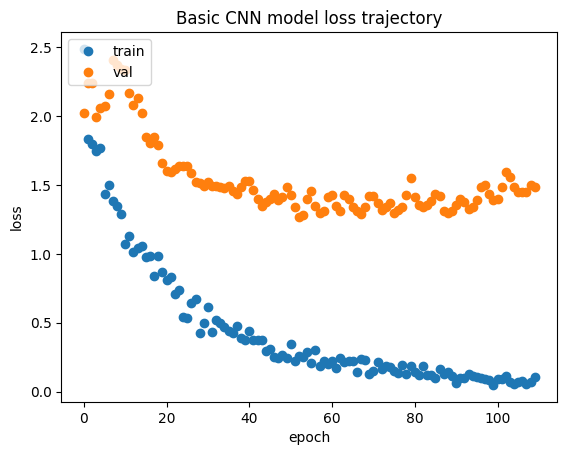

In [11]:
# Plotting accuracy trajectory
plt.plot(basic_cnn_model_results.history['accuracy'])
plt.plot(basic_cnn_model_results.history['val_accuracy'])
plt.title('Basic CNN model accuracy trajectory')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

# Plotting loss trajectory
plt.plot(basic_cnn_model_results.history['loss'],'o')
plt.plot(basic_cnn_model_results.history['val_loss'],'o')
plt.title('Basic CNN model loss trajectory')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [12]:
## Testing the basic CNN model
cnn_score = basic_cnn_model.evaluate(x_test, y_test, verbose=0)
print('Test accuracy of the CNN model:',cnn_score[1])

Test accuracy of the CNN model: 0.4040631949901581


In [13]:
p1_mask = (person_test == 1).flatten()
x_test = x_test[p1_mask]
y_test = y_test[p1_mask]

print(x_test.shape)
print(y_test.shape)

(50, 500, 1, 22)
(50, 4)


In [14]:
cnn_score = basic_cnn_model.evaluate(x_test, y_test, verbose=0)
print('Test accuracy of the CNN model, single person:',cnn_score[1])

Test accuracy of the CNN model, single person: 0.5400000214576721
